# Chan et al. 2021 — Lung (SCLC) · 04 Expression (unconditional EMT-TF step)

*(Renumbered from 06: with Gate 1 = GO, Gate 2 = GO, Gate 3 = NA the manifold is non-branching, so
the branching-only `04_correlation` / `05_modules` notebooks are not produced; the unconditional
EMT-TF step becomes the final notebook, numbered 04.)*

EMT-TF expression overlaid on the manifold. A widened mesenchymal panel (Snail/Zeb/Twist **and**
FOXC/PRRX families) scored on this dataset, gated on detectable expression, ordered by pseudotime.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load `signatures.h5ad`; use house linear layout

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 50998 | pseudotime range 0.0 -> 11.72


### EMT-TF panel — detection-gated, pseudotime-ordered
Widened panel beyond Snail/Zeb/Twist to include FOXC/PRRX. For each TF: fraction expressing, mean in
the early (root) vs late (terminus) pseudotime tercile, and Spearman vs pseudotime. Endpoint markers
are drawn from factors above the 3% detection floor — the most root-leaning and most
terminus-leaning.

In [6]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')
print('note: ZEB1 is the most-expressed factor but pseudotime-flat, so it is not an endpoint marker.')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
TWIST1      0.139       0.134      0.094    -0.094    EARLY(root)
  ZEB2      0.122       0.087      0.083    -0.064    EARLY(root)
  ZEB1      0.226       0.167      0.170    -0.047 LATE(terminus)
 PRRX1      0.016       0.009      0.006    -0.046    EARLY(root)
 FOXC1      0.154       0.100      0.111    -0.034 LATE(terminus)
 SNAI2      0.055       0.035      0.037    -0.030 LATE(terminus)
 FOXC2      0.016       0.009      0.008    -0.025    EARLY(root)
 PRRX2      0.024       0.013      0.012    -0.021    EARLY(root)
 SNAI1      0.121       0.068      0.086    -0.013 LATE(terminus)
TWIST2      0.004       0.001      0.004     0.023 LATE(terminus)

derived pair: TWIST1 (early/root) <-> SNAI1 (late/terminus)
note: ZEB1 is the most-expressed factor but pseudotime-flat, so it is not an endpoint marker.


### Deliverable — `expression.pdf`: thresholded expressers on a grey manifold
House style: categorical overlay (not a continuous colormap). Cells above the upper-quartile of
expression among expressers are coloured per TF over the grey manifold; the more abundant factor is
drawn first so the sparser one stays visible. `figsize=(3.5,1.5)`, `size=6`.

overlay thresholds (upper quartile among expressers): {'TWIST1': 0.968, 'SNAI1': 0.707} | cells shown: {'TWIST1': 1768, 'SNAI1': 1547}
TWIST1: 13.9% expressing; 1768 shown, mean pt of shown = 0.52 (all = 0.56)
SNAI1: 12.1% expressing; 1547 shown, mean pt of shown = 0.68 (all = 0.56)
saved expression.pdf


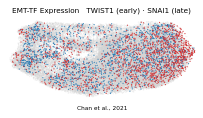

In [8]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, mean pt of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')